In [19]:
# package import
import numpy as np
from numpy import arange
import pandas as pd
from pandas import read_csv
from pandas import set_option
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score



import ipywidgets as widgets
from ipywidgets import interact

In [20]:
starting_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
    "ord__hand_sanitizer_frequency",
    "ord__i12_health_13",
    "ord__i12_health_22",
    "ord__i12_health_25",
]

In [21]:
expanded_cols = starting_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]

In [22]:
compact_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
]

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metric_rows = []

for name in models_to_plot:
    y_pred = y_pred_by_model[name]

    metric_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df)

,model,accuracy,precision,recall,f1
0,all_61,0.766719,0.626923,0.445355,0.520767
1,starting_model,0.758165,0.606178,0.428962,0.502400
2,expanded_model,0.768274,0.633858,0.439891,0.519355
3,compact_model,0.745723,0.565657,0.459016,0.506787


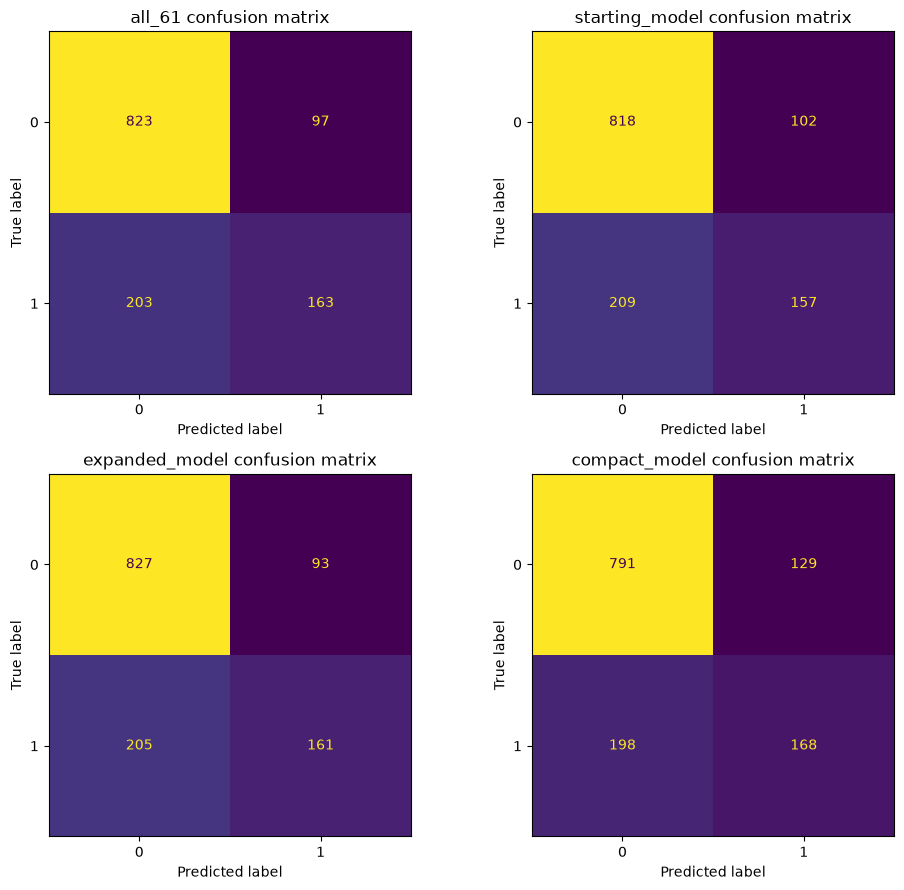

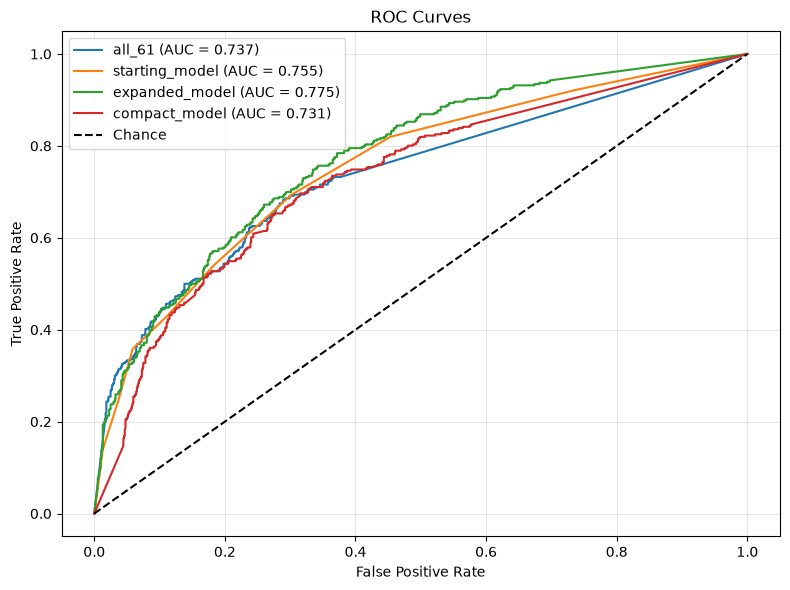

,model,AUC
0,all_61,0.736581
1,starting_model,0.755212
2,expanded_model,0.775138
3,compact_model,0.731378


In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc

# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, name in zip(axes.flat, models_to_plot):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred_by_model[name],
        labels=[0, 1],
        display_labels=["0", "1"],
        ax=ax,
        colorbar=False,
    )
    ax.set_title(f"{name} confusion matrix")

plt.tight_layout()
plt.show()


# ROC curves and AUC
plt.figure(figsize=(8, 6))
auc_results = []

for name in models_to_plot:
    fpr, tpr, _ = roc_curve(
        y_test,
        y_score_by_model[name],
        pos_label=1,
    )
    model_auc = auc(fpr, tpr)
    auc_results.append({"model": name, "AUC": model_auc})

    plt.plot(fpr, tpr, label=f"{name} (AUC = {model_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame(auc_results))